# Figure 3 - Analysis Code

In [1]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import matplotlib.pyplot as plt

In [2]:
DATA_PATH = "../../cnt-data/"

In [3]:
def get_patient_hup_ids(directory):
    # List all files in the directory
    files = os.listdir(directory)

    # Filter out files based on the given pattern and extract patient_hup_id as integers
    patient_hup_ids = [
        int(f.split("_")[1].split(".")[0]) for f in files if f.startswith("HUP_")
    ]

    return patient_hup_ids


TABLES_PATH = os.path.join(DATA_PATH, "giant_new_tables")
completed_hup_ids = get_patient_hup_ids(TABLES_PATH)
completed_hup_ids.sort()
len(completed_hup_ids)

68

## Figure 3(A)

In [4]:
def get_seizure_data(hourly_patient_features_df):
    seizure_indices = hourly_patient_features_df[
        hourly_patient_features_df["had_seizure"] >= 1
    ].index

    valid_seizure_indices = [
        idx
        for i, idx in enumerate(seizure_indices)
        if i == 0 or (seizure_indices[i] - seizure_indices[i - 1]) >= 5 * 60
    ]

    seizure_data = []

    for idx in valid_seizure_indices:
        seizure_time = hourly_patient_features_df.loc[idx, "emu_minute"]

        window = hourly_patient_features_df[
            (hourly_patient_features_df["emu_minute"] >= seizure_time - 60)
            & (hourly_patient_features_df["emu_minute"] < seizure_time)
        ]
        if len(window["synchrony_broadband"]) == 0 or np.all(
            np.isnan(window["synchrony_broadband"])
        ):
            continue  # Skip the rest of the current iteration

        avg_synchrony = np.nanmedian(window["synchrony_broadband"])
        avg_med_load = np.nanmedian(window["med_sum_no_lorazepam_raw"])

        if avg_synchrony < 0.8:
            seizure_data.append((avg_med_load, avg_synchrony))

    return seizure_data

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.030
Model:                            OLS   Adj. R-squared:                  0.024
Method:                 Least Squares   F-statistic:                     4.712
Date:                Sun, 23 Nov 2025   Prob (F-statistic):             0.0315
Time:                        19:25:51   Log-Likelihood:                 325.83
No. Observations:                 154   AIC:                            -647.7
Df Residuals:                     152   BIC:                            -641.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.1253      0.004     35.616      0.0

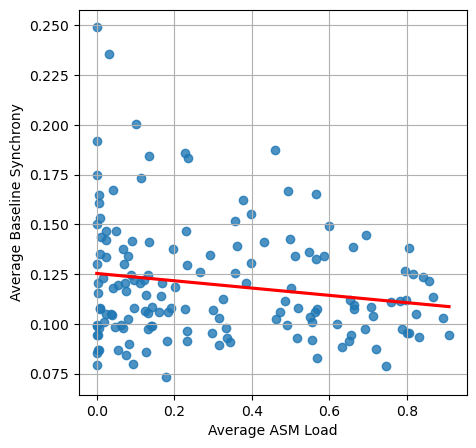

In [5]:
# Accumulate data from all patients
all_seizures_data = []

for patient_hup_id in completed_hup_ids:
    hourly_patient_features_df = pd.read_csv(
        os.path.join(TABLES_PATH, f"HUP_{str(patient_hup_id)}.csv")
    )
    all_seizures_data.extend(get_seizure_data(hourly_patient_features_df))

# Scatter plot
plt.figure(figsize=(5, 5))
avg_med_loads, avg_synchronies = zip(*all_seizures_data)

# Convert tuples to lists
avg_med_loads_list = list(avg_med_loads)
avg_synchronies_list = list(avg_synchronies)

# Fit an OLS regression model
X = sm.add_constant(avg_med_loads_list)  # Adding a constant for the intercept
model = sm.OLS(avg_synchronies_list, X).fit()

# Print out the statistics
print(model.summary())

sns.regplot(
    x=avg_med_loads_list,
    y=avg_synchronies_list,
    scatter=True,
    line_kws={"color": "red"},
    ci=None,
)

plt.xlabel("Average ASM Load")
plt.ylabel("Average Baseline Synchrony")
plt.grid(True)
plt.show()

## Figure 3 (B)

In [6]:
def get_post_seizure_data(hourly_patient_features_df):
    """
    POST-ICTAL ANALYSIS:
    For a given patient, get the avg med load and avg synchrony in the
    60-minute window *after* each valid seizure.
    """
    seizure_indices = hourly_patient_features_df[
        hourly_patient_features_df["had_seizure"] >= 1
    ].index

    # Find seizures separated by at least 2*60 = 120 minutes
    valid_seizure_indices = [
        idx
        for i, idx in enumerate(seizure_indices)
        if i == 0 or (seizure_indices[i] - seizure_indices[i - 1]) >= 5 * 60
    ]

    seizure_data = []

    for idx in valid_seizure_indices:
        seizure_time = hourly_patient_features_df.loc[idx, "emu_minute"]

        # --- MODIFIED LOGIC ---
        # Define the 60-minute window *AFTER* the seizure
        window = hourly_patient_features_df[
            (hourly_patient_features_df["emu_minute"] > seizure_time)
            & (hourly_patient_features_df["emu_minute"] <= seizure_time + 60)
        ]
        # --- END MODIFIED LOGIC ---

        if len(window["synchrony_broadband"]) == 0 or np.all(
            np.isnan(window["synchrony_broadband"])
        ):
            continue  # Skip if no data in window

        avg_synchrony = np.nanmedian(window["synchrony_broadband"])
        avg_med_load = np.nanmedian(window["med_sum_no_lorazepam_raw"])

        # Filter out potential high-synchrony outliers
        if avg_synchrony < 0.8:
            seizure_data.append((avg_med_load, avg_synchrony))

    return seizure_data

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.017
Model:                            OLS   Adj. R-squared:                  0.010
Method:                 Least Squares   F-statistic:                     2.592
Date:                Sun, 23 Nov 2025   Prob (F-statistic):              0.110
Time:                        19:25:51   Log-Likelihood:                 312.45
No. Observations:                 152   AIC:                            -620.9
Df Residuals:                     150   BIC:                            -614.9
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.1243      0.004     33.054      0.0

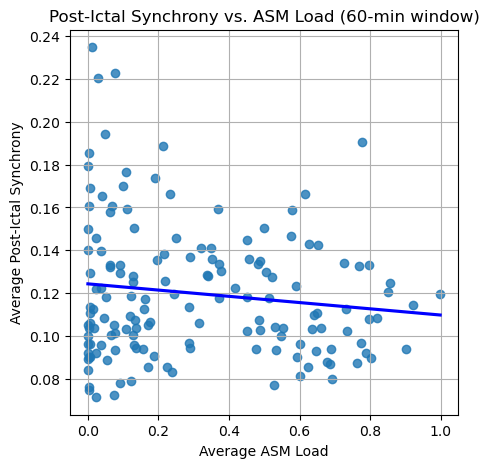

In [7]:
all_seizures_data_post = []
for patient_hup_id in completed_hup_ids:
    try:
        hourly_patient_features_df = pd.read_csv(
            os.path.join(TABLES_PATH, f"HUP_{str(patient_hup_id)}.csv")
        )
        all_seizures_data_post.extend(get_post_seizure_data(hourly_patient_features_df))
    except Exception as e:
        print(f"Could not process patient {patient_hup_id} for post-ictal: {e}")

if not all_seizures_data_post:
    print("No valid post-seizure data found.")
else:
    # Unzip data
    avg_med_loads_post, avg_synchronies_post = zip(*all_seizures_data_post)
    avg_med_loads_list_post = list(avg_med_loads_post)
    avg_synchronies_list_post = list(avg_synchronies_post)

    # Fit an OLS regression model
    X_post = sm.add_constant(avg_med_loads_list_post)  # Adding a constant
    model_post = sm.OLS(avg_synchronies_list_post, X_post).fit()

    # Print out the statistics
    print(model_post.summary())

    # Scatter plot
    plt.figure(figsize=(5, 5))
    sns.regplot(
        x=avg_med_loads_list_post,
        y=avg_synchronies_list_post,
        scatter=True,
        line_kws={"color": "blue"},  # Changed color
        ci=None,
    )
    plt.xlabel("Average ASM Load")
    plt.ylabel("Average Post-Ictal Synchrony")  # Changed label
    plt.title("Post-Ictal Synchrony vs. ASM Load (60-min window)")
    plt.grid(True)
    plt.show()
